In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
DATA_RAW = Path("../data/raw") #where the raw data is (never changed)
DATA_CLEAN = Path("../data/processed") #where the cleaned data is saved
FIGURES_DIR = Path("../outputs/visualizations") #where the charts are saved

DATA_CLEAN.mkdir(parents=True, exist_ok=True) #make the folders if they don't exist yet
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SQFT_PER_ACRE = 43560 #1 acre = 43,560 square feet

In [3]:
sf_parcels_gdf = gpd.read_parquet(DATA_RAW / "sf_parcels.parquet")
mtc_sb79_zones_gdf = gpd.read_file(DATA_RAW / "mtc_sb79_tod_zones.geojson")

print("parcels:", sf_parcels_gdf.shape, "| CRS:", sf_parcels_gdf.crs)
print("SB 79 zones:", mtc_sb79_zones_gdf.shape, "| CRS:", mtc_sb79_zones_gdf.crs)
sf_parcels_gdf.head()

parcels: (236575, 11) | CRS: {"$schema": "https://proj.org/schemas/v0.7/projjson.schema.json", "type": "GeographicCRS", "name": "WGS 84", "datum_ensemble": {"name": "World Geodetic System 1984 ensemble", "members": [{"name": "World Geodetic System 1984 (Transit)"}, {"name": "World Geodetic System 1984 (G730)"}, {"name": "World Geodetic System 1984 (G873)"}, {"name": "World Geodetic System 1984 (G1150)"}, {"name": "World Geodetic System 1984 (G1674)"}, {"name": "World Geodetic System 1984 (G1762)"}, {"name": "World Geodetic System 1984 (G2139)"}, {"name": "World Geodetic System 1984 (G2296)"}], "ellipsoid": {"name": "WGS 84", "semi_major_axis": 6378137, "inverse_flattening": 298.257223563}, "accuracy": "2.0", "id": {"authority": "EPSG", "code": 6326}}, "coordinate_system": {"subtype": "ellipsoidal", "axis": [{"name": "Geodetic latitude", "abbreviation": "Lat", "direction": "north", "unit": "degree"}, {"name": "Geodetic longitude", "abbreviation": "Lon", "direction": "east", "unit": "deg

ERROR 1: PROJ: proj_create_from_database: Open of /srv/conda/envs/notebook/share/proj failed


,mapblklot,blklot,block_num,from_address_num,street_name,street_type,zoning_code,zoning_district,active,analysis_neighborhood,geometry
0,7261001,7261001,7261,4501,OCEAN,AVE,RH-1(D),"RESIDENTIAL- HOUSE, ONE FAMILY- DETACHED",True,Sunset/Parkside,"MULTIPOLYGON (((-122.49185 37.73179, -122.4918..."
1,2649027,2649027,2649,53,EUREKA,ST,RH-3,"RESIDENTIAL- HOUSE, THREE FAMILY",True,Castro/Upper Market,"MULTIPOLYGON (((-122.43823 37.76146, -122.4382..."
2,3702392,3702803,3702,None,None,None,C-3-G,DOWNTOWN- GENERAL,True,South of Market,"MULTIPOLYGON (((-122.41262 37.77804, -122.4131..."
3,3146034P,3146034P,3146,716,CAYUGA,AVE,RH-1,"RESIDENTIAL- HOUSE, ONE FAMILY",True,Outer Mission,"MULTIPOLYGON (((-122.43717 37.7267, -122.43757..."
4,2330006A,2330006A,2330,2299,19TH,AVE,RTO-C,RESIDENTIAL TRANSIT ORIENTED DISTRICT - C,True,Sunset/Parkside,"MULTIPOLYGON (((-122.47632 37.745, -122.47634 ..."


In [4]:
#check the column types and missing values
sf_parcels_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 236575 entries, 0 to 236574
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   mapblklot              236303 non-null  object  
 1   blklot                 236575 non-null  object  
 2   block_num              236575 non-null  object  
 3   from_address_num       211709 non-null  object  
 4   street_name            211709 non-null  object  
 5   street_type            209014 non-null  object  
 6   zoning_code            235498 non-null  object  
 7   zoning_district        235497 non-null  object  
 8   active                 236575 non-null  bool    
 9   analysis_neighborhood  236303 non-null  object  
 10  geometry               236303 non-null  geometry
dtypes: bool(1), geometry(1), object(9)
memory usage: 18.3+ MB


In [5]:
mtc_sb79_zones_gdf["zone_label"].value_counts()

zone_label
Tier 2 - 200ft           339
Tier 2 - Quarter Mile     82
Tier 1 - 200ft            71
Tier 1 - Quarter Mile     60
Tier 2 - Half Mile        59
Tier 1 - Half Mile        54
Name: count, dtype: int64

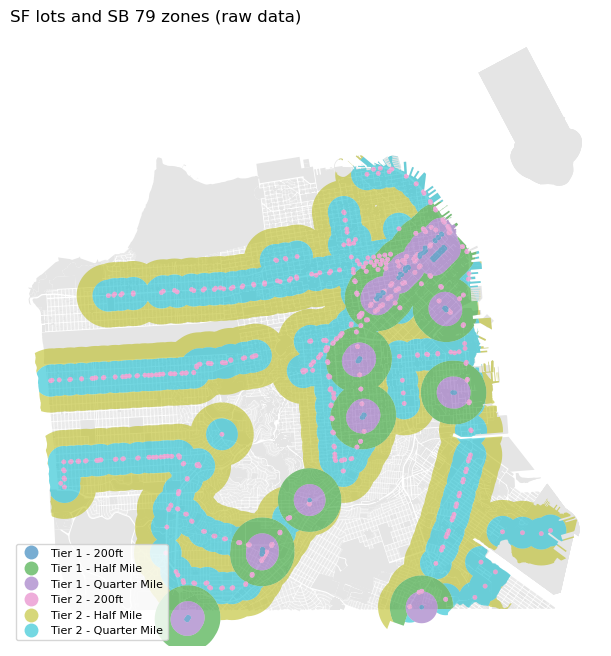

In [6]:
#SB 79 zones on top of SF lots
fig, ax = plt.subplots(figsize=(8, 8))
sf_parcels_gdf.plot(ax=ax, color="#e5e5e5", linewidth=0)
mtc_sb79_zones_gdf.cx[-122.52:-122.35, 37.70:37.84].plot(ax=ax, column="zone_label", legend=True, alpha=0.6,
                                                          legend_kwds={"loc": "lower left", "fontsize": 8})
ax.set_xlim(-122.52, -122.35)
ax.set_ylim(37.70, 37.84)
ax.set_title("SF lots and SB 79 zones (raw data)", loc="left")
ax.set_axis_off()
plt.savefig(FIGURES_DIR / "sf_raw_data_look.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# STEP 2: Gather parcels

In [8]:
#keep only the columns we need
keep_parcel_columns = [
    "mapblklot", #the lot as drawn on the map (condo units in one building share one)
    "blklot", #block + lot number
    "block_num", #city block number
    "from_address_num", #street number
    "street_name",
    "street_type",
    "zoning_code", #zoning code (ex. RH-2, NCT-3); split lots look like "RH-1|RH-2"
    "zoning_district", #zoning district name (ex. RESIDENTIAL- HOUSE, TWO FAMILY)
    "analysis_neighborhood", #neighborhood name
    "active", #true = a current lot, false = a retired lot
    "geometry", #lot shape
]
rows_before = len(sf_parcels_gdf)
sf_parcels_gdf = sf_parcels_gdf[keep_parcel_columns]
print("rows:", rows_before, "->", len(sf_parcels_gdf), "| columns:", sf_parcels_gdf.shape[1])

rows: 236575 -> 236575 | columns: 11


In [9]:
print("rows:", len(sf_parcels_gdf), "| unique map lots:", sf_parcels_gdf["mapblklot"].nunique())

rows_before = len(sf_parcels_gdf)
sf_parcels_gdf = sf_parcels_gdf.drop_duplicates(subset="mapblklot")
print("rows:", rows_before, "->", len(sf_parcels_gdf))

rows: 236575 | unique map lots: 163290
rows: 236575 -> 163291


In [10]:
#an empty zoning code is stored as "" instead of missing, so turn "" into missing first
sf_parcels_gdf["zoning_code"] = sf_parcels_gdf["zoning_code"].replace("", None)
print(sf_parcels_gdf[["geometry", "zoning_code"]].isna().sum())

rows_before = len(sf_parcels_gdf)
sf_parcels_gdf = sf_parcels_gdf.dropna(subset=["geometry", "zoning_code"])
sf_parcels_gdf = sf_parcels_gdf.drop(columns=["active"]) #every row is active now
print("rows:", rows_before, "->", len(sf_parcels_gdf))

geometry         1
zoning_code    806
dtype: int64
rows: 163291 -> 162485


In [11]:
sf_parcels_gdf = sf_parcels_gdf.to_crs(2227)
mtc_sb79_zones_gdf = mtc_sb79_zones_gdf.to_crs(2227)
print(sf_parcels_gdf.crs.name, "| unit:", sf_parcels_gdf.crs.axis_info[0].unit_name)
print("same CRS:", sf_parcels_gdf.crs == mtc_sb79_zones_gdf.crs)

#lot size in acres, from the shape
sf_parcels_gdf["acres"] = sf_parcels_gdf.area / SQFT_PER_ACRE
sf_parcels_gdf["acres"].describe().round(3) #a typical 25 x 100 ft SF lot is 0.057 acres

NAD83 / California zone 3 (ftUS) | unit: US survey foot
same CRS: True


count    162485.000
mean          0.218
std           7.672
min           0.000
25%           0.055
50%           0.065
75%           0.076
max        1505.635
Name: acres, dtype: float64

In [12]:
def dominant_zone(parcels, zones, zone_columns):
    """For each lot, find the zone that covers the most of its area.

    parcels: lots with "mapblklot" and geometry (EPSG:2227)
    zones: zone shapes in the same CRS
    zone_columns: the zone columns to keep (ex. ["zone_label"])
    returns one row per lot: mapblklot, the zone columns, overlap_area (sq ft)
    """
    #cut every lot into pieces where it overlaps each zone
    pieces = gpd.overlay(parcels[["mapblklot", "geometry"]], zones[zone_columns + ["geometry"]], how="intersection")
    pieces["overlap_area"] = pieces.area

    #for each lot keep the biggest piece = its dominant zone
    pieces = pieces.sort_values("overlap_area", ascending=False)
    pieces = pieces.drop_duplicates(subset="mapblklot")
    return pd.DataFrame(pieces[["mapblklot"] + zone_columns + ["overlap_area"]])

In [13]:
is_split = sf_parcels_gdf["zoning_code"].str.contains("|", regex=False)
print("split-zoned lots:", is_split.sum(), "of", len(sf_parcels_gdf))
sf_parcels_gdf.loc[is_split, "zoning_code"].value_counts().head(10)

split-zoned lots: 1059 of 162485


zoning_code
PM-R|RM-1            65
TI-MU|TI-OS          62
RH-1|RH-2            61
HP-RA|RM-1           34
TI-R|TI-OS           31
P|P                  28
TI-OS|TI-R           25
TI-MU|TI-MU|TI-OS    18
P|RM-1               18
NCD|RH-2             18
Name: count, dtype: int64

In [14]:
#SF zoning district shapes (only the two columns we need)
sf_zoning_gdf = gpd.read_file(DATA_RAW / "sf_zoning.geojson")[["zoning_sim", "districtname", "geometry"]]
sf_zoning_gdf = sf_zoning_gdf.to_crs(2227)
print("zoning district shapes:", len(sf_zoning_gdf), "| CRS:", sf_zoning_gdf.crs.name)

split_dominant = dominant_zone(sf_parcels_gdf[is_split], sf_zoning_gdf, ["zoning_sim", "districtname"])
print("split lots with a dominant district:", len(split_dominant))
split_dominant.head()

zoning district shapes: 10617 | CRS: NAD83 / California zone 3 (ftUS)
split lots with a dominant district: 1059


,mapblklot,zoning_sim,districtname,overlap_area
523,1300001,P,PUBLIC,6.558196e+07
3056,1700001,P,PUBLIC,4.420139e+07
1173,7283004,P,PUBLIC,2.620099e+07
1598,4591A010,HP-RA,SEE HUNTERS POINT REDEVELOPMENT PLAN,1.984958e+07
2226,4591A079,HP-RA,SEE HUNTERS POINT REDEVELOPMENT PLAN,1.804016e+07


In [15]:
#zone_name = the zoning district name we match to the spreadsheet
#one-zone lots: the district name already in the parcel file
#split lots: the dominant district from the overlay above
sf_parcels_gdf["zone_name"] = sf_parcels_gdf["zoning_district"]
sf_parcels_gdf = sf_parcels_gdf.merge(
    split_dominant[["mapblklot", "districtname"]], on="mapblklot", how="left", validate="one_to_one"
)
sf_parcels_gdf.loc[is_split.values, "zone_name"] = sf_parcels_gdf.loc[is_split.values, "districtname"]
sf_parcels_gdf = sf_parcels_gdf.drop(columns=["districtname"])

print("lots with no zone name:", sf_parcels_gdf["zone_name"].isna().sum())

lots with no zone name: 0


In [16]:
MIN_SHARE_IN_SB79 = 0.5 #at least half the lot must be inside SB 79 rings

#only the zones that touch SF (MTC's file covers the whole Bay Area)
sf_zones_gdf = mtc_sb79_zones_gdf[mtc_sb79_zones_gdf.intersects(sf_parcels_gdf.union_all().envelope)]
print("SB 79 zones touching SF:", len(sf_zones_gdf))

#to save time, only overlay the lots that touch an SB 79 zone
touching = gpd.sjoin(sf_parcels_gdf[["mapblklot", "geometry"]], sf_zones_gdf[["geometry"]], predicate="intersects")
lots_touching = sf_parcels_gdf[sf_parcels_gdf["mapblklot"].isin(touching["mapblklot"])]
print("lots touching an SB 79 zone:", len(lots_touching))

tier_dominant = dominant_zone(lots_touching, sf_zones_gdf, ["zone_id", "zone_label"])
tier_dominant = tier_dominant.rename(columns={"zone_label": "tier_zone_label"})

#how much of each lot is inside ANY SB 79 ring
pieces = gpd.overlay(lots_touching[["mapblklot", "geometry"]], sf_zones_gdf[["geometry"]], how="intersection")
pieces["piece_area"] = pieces.area
share_inside = pieces.groupby("mapblklot")["piece_area"].sum().reset_index()
tier_dominant = tier_dominant.merge(share_inside, on="mapblklot", how="left", validate="one_to_one")

SB 79 zones touching SF: 336
lots touching an SB 79 zone: 129819


In [17]:
#add the tier to every lot (lots outside SB 79 get no tier = missing)
rows_before = len(sf_parcels_gdf)
sf_parcels_gdf = sf_parcels_gdf.merge(tier_dominant, on="mapblklot", how="left", validate="one_to_one")
sf_parcels_gdf["share_in_sb79"] = sf_parcels_gdf["piece_area"] / sf_parcels_gdf.area
sf_parcels_gdf = sf_parcels_gdf.drop(columns=["piece_area"])

#lots with less than half their area inside SB 79 are treated as outside
mostly_outside = sf_parcels_gdf["share_in_sb79"] < MIN_SHARE_IN_SB79
print("lots touching a ring but mostly outside (treated as no tier):", mostly_outside.sum())
sf_parcels_gdf.loc[mostly_outside, ["zone_id", "tier_zone_label", "overlap_area"]] = None

print("rows:", rows_before, "->", len(sf_parcels_gdf))
print("lots with an SB 79 tier:", sf_parcels_gdf["tier_zone_label"].notna().sum())
sf_parcels_gdf["tier_zone_label"].value_counts()

lots touching a ring but mostly outside (treated as no tier): 1182
rows: 162485 -> 162485
lots with an SB 79 tier: 128637


tier_zone_label
Tier 2 - Quarter Mile    51241
Tier 2 - Half Mile       46674
Tier 1 - Half Mile       19150
Tier 1 - Quarter Mile     6816
Tier 2 - 200ft            4499
Tier 1 - 200ft             257
Name: count, dtype: int64

In [18]:
#the SF and SB79 tabs of cyplan101_zoning.xlsx, saved as csv (File > Save As > CSV, one tab at a time)
sf_scale_df = pd.read_csv(DATA_RAW / "zoning_sheet_SF.csv")
sb79_scale_df = pd.read_csv(DATA_RAW / "zoning_sheet_SB79.csv").dropna(how="all")

#zoning_description looks like "RESIDENTIAL- HOUSE, TWO FAMILY — houses ..."
#the part before " — " is the district name used in the parcel file
sf_scale_df["zone_name"] = sf_scale_df["zoning_description"].str.split(" — ").str[0]
sf_scale_df = sf_scale_df[["zone_name", "input_label", "type", "group_scale", "scale_reason"]]

print("SF zones in the spreadsheet:", len(sf_scale_df))
sb79_scale_df

SF zones in the spreadsheet: 119


,tier,radius,tier_zone_label,sb79_scale,max_height_sb79
0,1,200,Tier 1 - 200ft,6,95
1,1,1/4,Tier 1 - Quarter Mile,5,75
2,1,1/2,Tier 1 - Half Mile,4,65
3,2,200,Tier 2 - 200ft,5,85
4,2,1/4,Tier 2 - Quarter Mile,4,65
5,2,1/2,Tier 2 - Half Mile,3,55


In [19]:
#one district shows up under two names in the parcel file, so point both names to the same row
sf_parcels_gdf["zone_name"] = sf_parcels_gdf["zone_name"].replace(
    {"RESIDENTIAL TRANSIT ORIENTED DISTRICT": "RESIDENTIAL TRANSIT ORIENTED DISTRICT - 1"}
)

rows_before = len(sf_parcels_gdf)
sf_parcels_gdf = sf_parcels_gdf.merge(sf_scale_df, on="zone_name", how="left", validate="many_to_one")
print("rows:", rows_before, "->", len(sf_parcels_gdf))

#every lot should find its zone in the spreadsheet
no_match = sf_parcels_gdf["input_label"].isna()
print("lots whose zone is not in the spreadsheet:", no_match.sum())
sf_parcels_gdf.loc[no_match, "zone_name"].value_counts()

rows: 162485 -> 162485
lots whose zone is not in the spreadsheet: 0


Series([], Name: count, dtype: int64)

In [20]:
#add the SB 79 scale and height for each lot's tier and band
sf_parcels_gdf = sf_parcels_gdf.merge(
    sb79_scale_df[["tier_zone_label", "tier", "radius", "sb79_scale", "max_height_sb79"]],
    on="tier_zone_label", how="left", validate="many_to_one",
)
sf_parcels_gdf.groupby("tier_zone_label")["sb79_scale"].first()

tier_zone_label
Tier 1 - 200ft           6.0
Tier 1 - Half Mile       4.0
Tier 1 - Quarter Mile    5.0
Tier 2 - 200ft           5.0
Tier 2 - Half Mile       3.0
Tier 2 - Quarter Mile    4.0
Name: sb79_scale, dtype: float64

In [21]:
APPLY_SB79_WHERE_NO_HOUSING = False

sf_parcels_gdf["scale_before"] = sf_parcels_gdf["group_scale"]

#start with today's scale, then raise it wherever SB 79 allows more
sf_parcels_gdf["scale_after"] = sf_parcels_gdf["scale_before"]
sb79_is_higher = sf_parcels_gdf["sb79_scale"] > sf_parcels_gdf["scale_before"]
if not APPLY_SB79_WHERE_NO_HOUSING:
    sb79_is_higher = sb79_is_higher & (sf_parcels_gdf["scale_before"] > 0)
sf_parcels_gdf.loc[sb79_is_higher, "scale_after"] = sf_parcels_gdf.loc[sb79_is_higher, "sb79_scale"]

sf_parcels_gdf["scale_change"] = sf_parcels_gdf["scale_after"] - sf_parcels_gdf["scale_before"]
sf_parcels_gdf["upzoned"] = sf_parcels_gdf["scale_change"] > 0

#quick check inside SB 79: before vs after
in_sb79 = sf_parcels_gdf["tier_zone_label"].notna()
pd.crosstab(sf_parcels_gdf.loc[in_sb79, "scale_before"], sf_parcels_gdf.loc[in_sb79, "scale_after"])

scale_after,0.0,3.0,4.0,5.0,6.0
scale_before,,,,,
0.0,3055,0,0,0,0
1.0,0,22438,25668,2042,0
2.0,0,22217,36443,5281,23
3.0,0,23,545,207,0
4.0,0,0,2053,234,1
5.0,0,0,0,794,0
6.0,0,0,0,0,6785


In [22]:
#full copy: every SF lot, in or out of SB 79
sf_parcels_gdf.to_parquet(DATA_CLEAN / "sf_parcels_scaled_all.parquet")

#analysis file: only lots with an SB 79 tier
rows_before = len(sf_parcels_gdf)
sf_sb79_parcels_gdf = sf_parcels_gdf[sf_parcels_gdf["tier_zone_label"].notna()].copy()
print("rows:", rows_before, "->", len(sf_sb79_parcels_gdf))
print("acres in SB 79:", round(sf_sb79_parcels_gdf["acres"].sum()))

sf_sb79_parcels_gdf.to_parquet(DATA_CLEAN / "sf_sb79_parcels_scaled.parquet")
print("saved", len(sf_sb79_parcels_gdf), "SB 79 lots and", rows_before, "total lots")

rows: 162485 -> 128637
acres in SB 79: 21535
saved 128637 SB 79 lots and 162485 total lots
